Homework 4: Evaluation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from IPython.display import display
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical = df.select_dtypes(include=["object", "string"]).columns.tolist()
numerical = df.select_dtypes(include="number").columns.tolist()
del numerical[-1]

for c in categorical:
    df[c] = df[c].str.lower().str.replace(' ', '_')

categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [6]:
# Replacing missing values
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
# Splitting the dataset

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values
y_full_train = df_full_train.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']
del df_full_train['converted']


Q1: ROC AUC feature importance

Evaluate feature importance of numerical values. For each numerical value, use it as a score (prediction) and compute the AUC with the
`y` variable as ground truth. Use the training dataset.

If your AUC is < 0.5, invert this variable by putting "-" in front. AUC can go below 0.5 if the variable is negatively correlated with the target variable.

Which numerical variable (among the following 4) has the highest AUC?
- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [19]:
from sklearn.metrics import roc_auc_score

for n in numerical:
    auc = roc_auc_score(y_train, df_train[n])
    print(f'AUC(converted, {n}) = {auc:.3f}')

AUC(converted, annual_income) = 0.608
AUC(converted, number_of_courses_viewed) = 0.723
AUC(converted, interaction_count) = 0.765
AUC(converted, lead_score) = 0.788


A1: The variable `lead_score` has the highest AUC score.

### Q2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [20]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(df_val[categorical + numerical].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(f'AUC = {auc:.3f}')

AUC = 0.732


A2: The AUC of this model, on the validation dataset, is 0.732

### Q3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

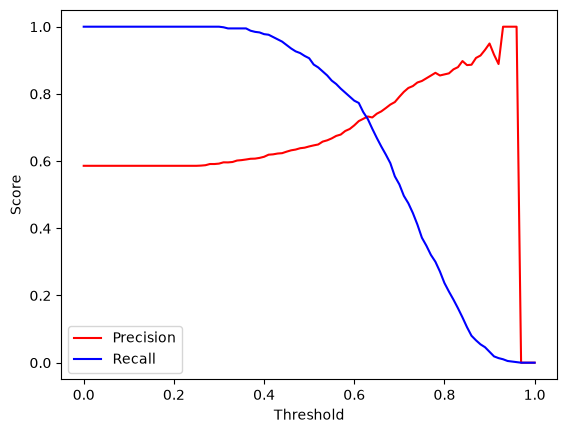

In [25]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    tp = np.sum(predict_positive & actual_positive)
    fp = np.sum(predict_positive & actual_negative)
    fn = np.sum(predict_negative & actual_positive)
    tn = np.sum(predict_negative & actual_negative)

    P = tp / (tp + fp) if (tp + fp) > 0 else 0
    R = tp / (tp + fn)

    scores.append((t, tp, fp, fn, tn, P, R))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'P', 'R']
df_scores = pd.DataFrame(scores, columns=columns)

plt.plot(df_scores['threshold'], df_scores['P'], color='red', label='Precision')
plt.plot(df_scores['threshold'], df_scores['R'], color='blue', label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [36]:
dif = np.abs(df_scores['P'] - df_scores['R'])
df_scores['dif'] = dif

intersect_threshold = df_scores[df_scores['dif'] > 0].sort_values(by='dif').iloc[0]['threshold']
print(f'Intersection threshold: t = {intersect_threshold:.2f}')

Intersection threshold: t = 0.63


A3: The threshold at which precision and recall intersect is `0.63`

### Q4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

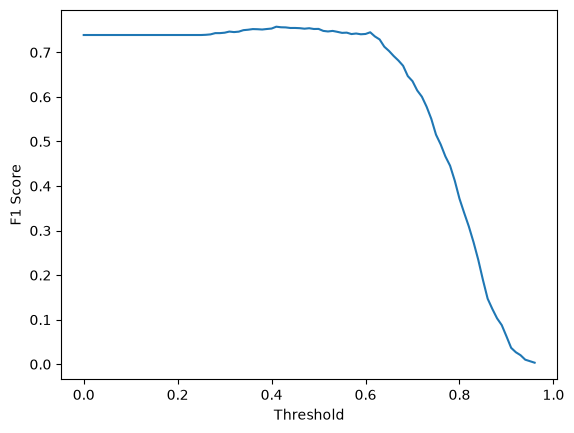

In [38]:
F1 = 2 * (df_scores['P'] * df_scores['R']) / (df_scores['P'] + df_scores['R'])
df_scores['F1'] = F1

plt.plot(df_scores['threshold'], df_scores['F1'])
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.show()

In [39]:
max_threshold = df_scores[df_scores['F1'] == df_scores['F1'].max()]['threshold'].values[0]
print(f'Max F1 threshold: t = {max_threshold:.2f}')

Max F1 threshold: t = 0.41


A4: F1 is maximal at the threshold `t=0.41`

### Q5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060